<a href="https://colab.research.google.com/github/aakriti1318/llm-inference-sandbox/blob/main/distillation_qwen_7b_0_5B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Distilling Qwen 2.5 7B Teacher model to Qwen 2.5 0.5B Student model

(A100)

* **Goal**: teach a small student model (Qwen 2.5 0.5B) to classify sentiment by learning a bigger teacher (Qwen 2.5 7B) that writes rationales (Reasoning) for each example

* **Pipeline**:
  1.   Load Data
  2.   Load Teacher model
  3.   Generate rationales
  4.   Free Teacher
  5.   Load Student
  6.   Build two-task training data
  7.   Train
  8.   Evaluate
  9.   Benchmark




## Step 0: Setup

In [1]:
!uv init

error: Project is already initialized in `/content` (`pyproject.toml` file exists)


In [6]:
!uv venv --clear

Using CPython 3.13.15 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate


In [7]:
!source .venv/bin/activate

Install the libraries we need. `bitsandbytes` lets us load the 7B teacher in 4-bit so it fits in GPU memory.

In [9]:
!uv pip uninstall -y torchvision torchaudio
!uv pip install -q -U transformers accelerate bitsandbytes datasets

Using Python 3.13.15 environment at: /usr


In [10]:
import huggingface_hub, transformers
print(huggingface_hub.__version__, transformers.__version__)

2.2.0 5.19.0


Import everything and check that a GPU is attached. If this prints `False`, fix the runtime type first.

In [11]:
import json, gc, torch
from tqdm.auto import tqdm
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, Trainer, TrainingArguments, DataCollatorForSeq2Seq

print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device Name:", torch.cuda.get_device_name(0))

GPU Available: True
GPU Device Name: NVIDIA A100-SXM4-40GB


Set the key settings in one place so they're easy to change later. Start small (1000 train examples) to keep it fast; scale up once it works.

In [19]:
Teacher = "Qwen/Qwen2.5-7B"
Student = "Qwen/Qwen2.5-0.5B"
n_train = 1000 # examples we ask the teacher to explain
n_val = 200
max_len = 256
ID2LABEL = {0: "negative", 1: "positive"}

## Step 1 - Load the dataset

SST-2 is a movie-review sentiment dataset (0 = negative, 1 = positive). We take a small train slice and use the official validation split for evaluation, because the test split has no labels.

In [14]:
ds = load_dataset("nyu-mll/glue", "sst2")
train = ds["train"].shuffle(seed=42).select(range(n_train))
val = ds["validation"].shuffle(seed=42).select(range(n_val))
print(train[0])
print(len(train), len(val))

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

{'sentence': 'klein , charming in comedies like american pie and dead-on in election , ', 'label': 1, 'idx': 32326}
1000 200


## Step 2 - Load the Teacher (Qwen2.5-7B, 4-bit)
Load Qwen2.5-7B-Instruct with 4-bit quantization (about 5-6 GB). `padding_side='left'` is required for batched generation with decoder-only models.

In [18]:
bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
)
t_tok = AutoTokenizer.from_pretrained(Teacher, padding_side='left')
teacher = AutoModelForCausalLM.from_pretrained(Teacher, quantization_config=bnb, device_map="auto")
teacher.eval()

config.json:   0%|          | 0.00/686 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(152064, 3584)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear4bit(in_features=3584, out_features=3584, bias=True)
          (k_proj): Linear4bit(in_features=3584, out_features=512, bias=True)
          (v_proj): Linear4bit(in_features=3584, out_features=512, bias=True)
          (o_proj): Linear4bit(in_features=3584, out_features=3584, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear4bit(in_features=3584, out_features=18944, bias=False)
          (up_proj): Linear4bit(in_features=3584, out_features=18944, bias=False)
          (down_proj): Linear4bit(in_features=18944, out_features=3584, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((3584,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((3584,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm

A helper that sends a *batch* of prompts to the teacher and returns its answers. Batching is much faster than one example at a time (the old notebook looped one by one).

In [20]:
def teacher_generate(prompts, max_new_tokens = 100):
  texts = [t_tok.apply_chat_template([{"role": "user", "content": p}],
                                     tokenize = False,
                                     add_generation_prompt = True) for p in prompts]
  enc = t_tok(texts, return_tensors="pt", padding=True).to(teacher.device)
  with torch.no_grad():
    out = teacher.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
  return [s.strip() for s in t_tok.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)]

## Step 3 - Sanity Check the teacher model
Measure the teacher's zero-shot accuracy on 100 validation examples. If it's weak here, its rationales will be weak too, so we check before spending time generating.

In [23]:
pos_ids = [t_tok.encode(w, add_special_tokens=False)[0] for w in ["positive", "Positive"]]
neg_ids = [t_tok.encode(w, add_special_tokens=False)[0] for w in ["negative", "Negative"]]

def teacher_classify(sentences):
    texts = [t_tok.apply_chat_template(
                [{"role": "user", "content":
                  f'Review: "{s}"\nIs the sentiment positive or negative? Reply with one word.'}],
                tokenize=False, add_generation_prompt=True) for s in sentences]
    enc = t_tok(texts, return_tensors="pt", padding=True).to(teacher.device)
    with torch.no_grad():
        logits = teacher(**enc).logits[:, -1, :]   # scores for the next token
    pos = logits[:, pos_ids].logsumexp(-1)
    neg = logits[:, neg_ids].logsumexp(-1)
    return (pos > neg).long().tolist()

preds = []
for i in range(0, len(sample), 20):
    preds += teacher_classify([x["sentence"] for x in sample.select(range(i, min(i+20, len(sample))))])

print("Accuracy:", sum(p == x["label"] for p, x in zip(preds, sample)) / len(sample))

Accuracy: 0.96


In [24]:
for p, x in list(zip(preds, sample))[:15]:
    print(repr(p), "| true:", ID2LABEL[x["label"]])

1 | true: positive
1 | true: positive
1 | true: positive
1 | true: positive
1 | true: positive
0 | true: negative
1 | true: positive
0 | true: negative
1 | true: positive
0 | true: negative
0 | true: negative
0 | true: positive
1 | true: positive
0 | true: positive
1 | true: positive


## Step 4 - Generate Rationales
For each training review we tell the teacher the *correct* label and ask it to explain why. Giving it the label keeps the rationales consistent with the ground truth.

In [25]:
def rationale_prompt(x):
  return (f'Review: "{x["sentence"]}"\n'
  f'The sentiment of this review is {ID2LABEL[x["label"]]}. '
            'In 2-3 short sentences, explain the reasoning that leads to this sentiment. '
            'Do not just restate the label.')

Run the teacher over the training set in batches of 16 (about 5 min on a A100). Each result stores the sentence, the label, and the rationale.

In [27]:
data, BS = [], 16
for i in tqdm(range(0, len(train), BS)):
  batch = train.select(range(i, min(i+BS, len(train))))
  rats = teacher_generate([rationale_prompt(x) for x in batch], max_new_tokens=100)
  for x, r in zip(batch, rats):
      data.append({"sentence": x["sentence"], "label": x["label"], "rationale": r})

print(json.dumps(data[:2], indent=2))

  0%|          | 0/63 [00:00<?, ?it/s]

[
  {
    "sentence": "klein , charming in comedies like american pie and dead-on in election , ",
    "label": 1,
    "rationale": "The sentiment of this review is positive because it praises Klein's acting abilities, highlighting his charm in comedies and his accuracy in serious roles. The use of words like \"charming\" and \"dead-on\" indicates a favorable opinion of Klein's performance."
  },
  {
    "sentence": "be fruitful ",
    "label": 1,
    "rationale": "The sentiment of this review is positive because the phrase \"be fruitful\" suggests a sense of growth, success, and productivity. This could imply that the product or service being reviewed has been effective and beneficial in some way."
  }
]


Save the rationales to disk so you never have to regenerate them if the session disconnects.

In [28]:
with open("rationales.json", "w") as f:
    json.dump(data, f)
# To keep it across sessions:
from google.colab import drive; drive.mount('/content/drive')
!cp rationales.json /content/drive/MyDrive/

Mounted at /content/drive


Quick quality filter: drop rationales that are empty or very short. Always read a few by eye, because bad rationales hurt the student.

In [29]:
data = [d for d in data if len(d["rationale"]) > 20]
print(len(data), "examples kept")
for d in data[:3]:
    print(ID2LABEL[d["label"]], "|", d["sentence"], "\n ->", d["rationale"], "\n")

1000 examples kept
positive | klein , charming in comedies like american pie and dead-on in election ,  
 -> The sentiment of this review is positive because it praises Klein's acting abilities, highlighting his charm in comedies and his accuracy in serious roles. The use of words like "charming" and "dead-on" indicates a favorable opinion of Klein's performance. 

positive | be fruitful  
 -> The sentiment of this review is positive because the phrase "be fruitful" suggests a sense of growth, success, and productivity. This could imply that the product or service being reviewed has been effective and beneficial in some way. 

positive | soulful and  
 -> The sentiment of this review is positive because the word "soulful" is often associated with something that is deeply emotional and moving, which suggests that the reviewer found the subject to be impactful and resonant. The use of the word "and" implies that there is more to the review, but the given text does not provide enough info

## Step 5 - Free the teacher's memory

We're done with the teacher, so delete it and clear the GPU cache. Otherwise the student has less memory to train with.

In [30]:
del teacher
gc.collect(); torch.cuda.empty_cache()
print(torch.cuda.memory_allocated()/1e9, "GB in use")

5.861636096 GB in use


## Step 6 - Load the student (0.5B)

Load the small Qwen as a causal LM (decoder-only, so it generates text rather than using a classification head). We keep weights in float32 and let the Trainer use fp16 mixed precision, which is stable on T4.

In [32]:
s_tok = AutoTokenizer.from_pretrained(Student)
student = AutoModelForCausalLM.from_pretrained(Student, torch_dtype=torch.float32).to("cuda")
print(sum(p.numel() for p in student.parameters()) / 1e6, "M parameters")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

494.032768 M parameters


## Step 7 - Baseline before training

A helper that asks the student for a label and measures accuracy. It uses the `[label]` prompt format we'll train on. We run it *before* training to get a baseline to beat.

In [33]:
def label_prompt(sentence):
    return f"[label] Review: {sentence}\nSentiment:"

def evaluate_student(model, dataset, bs=32):
    model.eval(); s_tok.padding_side = "left"
    correct = 0
    for i in range(0, len(dataset), bs):
        batch = dataset.select(range(i, min(i + bs, len(dataset))))
        enc = s_tok([label_prompt(x["sentence"]) for x in batch], return_tensors="pt", padding=True).to("cuda")
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            out = model.generate(**enc, max_new_tokens=3, do_sample=False)
        texts = s_tok.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
        for t, x in zip(texts, batch):
            correct += ("positive" in t.lower()) == bool(x["label"]) and ("positive" in t.lower() or "negative" in t.lower())
    return correct / len(dataset)

print("Student accuracy BEFORE training:", evaluate_student(student, val))

Student accuracy BEFORE training: 0.895


## Step 8 - Build the two-task training data

This is the heart of *Distilling Step-by-Step*. Each example becomes **two** training samples:
1. `[label]` task: review → sentiment word
2. `[rationale]` task: review → the teacher's reasoning

Learning to explain helps the student get the label right, and at test time we only use the `[label]` prompt.

In [34]:
def build_examples(d):
    return [
        (label_prompt(d["sentence"]), ID2LABEL[d["label"]]),
        (f"[rationale] Review: {d['sentence']}\nReasoning:", d["rationale"]),
    ]

pairs = [p for d in data for p in build_examples(d)]
print(len(pairs), "training samples"); print(pairs[0]); print(pairs[1])

2000 training samples
('[label] Review: klein , charming in comedies like american pie and dead-on in election , \nSentiment:', 'positive')
('[rationale] Review: klein , charming in comedies like american pie and dead-on in election , \nReasoning:', 'The sentiment of this review is positive because it praises Klein\'s acting abilities, highlighting his charm in comedies and his accuracy in serious roles. The use of words like "charming" and "dead-on" indicates a favorable opinion of Klein\'s performance.')


Tokenize each (prompt, target) pair. We set the prompt part of `labels` to `-100` so the loss is computed **only on the target** (the answer or rationale), not on the prompt. We also add an end-of-sequence token so the model learns when to stop.

In [36]:
def encode(prompt, target):
    p = s_tok(prompt, add_special_tokens=False).input_ids
    t = s_tok(" " + target, add_special_tokens=False).input_ids + [s_tok.eos_token_id]
    ids = (p + t)[:max_len]
    labels = ([-100] * len(p) + t)[:max_len]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

train_ds = Dataset.from_list([encode(p, t) for p, t in pairs]).shuffle(seed=42)
print(train_ds)

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 2000
})


## Step 9 - Train

Set the training hyperparameters. Effective batch size is 8 x 2 = 16, learning rate is small (2e-5) because we're fine-tuning a pretrained model, and `fp16=True` speeds things up and saves memory.

In [38]:
import math

EPOCHS, BS, ACCUM = 3, 8, 2
steps_per_epoch = math.ceil(len(train_ds) / (BS * ACCUM))
total_steps = steps_per_epoch * EPOCHS
warmup = max(1, int(0.05 * total_steps))
print(f"{total_steps} total steps, {warmup} warmup steps")

args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BS,
    gradient_accumulation_steps=ACCUM,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=warmup,
    lr_scheduler_type="cosine",
    fp16=True,
    logging_steps=20,
    save_strategy="no",
    report_to="none",
)

375 total steps, 18 warmup steps


Build the Trainer. The collator pads each batch to the same length and pads `labels` with `-100`, so padding is ignored in the loss. We use the standard loss; the multi-task part comes from the data itself.

In [39]:
s_tok.padding_side = "right"
collator = DataCollatorForSeq2Seq(s_tok, padding=True, label_pad_token_id=-100)
trainer = Trainer(model=student, args=args, train_dataset=train_ds, data_collator=collator)

Start training. Watch the loss go down. It's a good sign if it falls steadily and doesn't hit zero immediately.

In [40]:
trainer.train()

Step,Training Loss
20,1.128270
40,1.002765
60,0.997538
80,0.976527
100,0.961972
120,0.913681
140,0.574887
160,0.429391
180,0.428172
200,0.422130


TrainOutput(global_step=375, training_loss=0.5148624947865804, metrics={'train_runtime': 102.6048, 'train_samples_per_second': 58.477, 'train_steps_per_second': 3.655, 'total_flos': 1114013705705472.0, 'train_loss': 0.5148624947865804, 'epoch': 3.0})

## Step 10 - Evaluate

Run the same accuracy test as the baseline. This should be much higher, which shows the student learned the task.

In [41]:
print("Student accuracy AFTER training:", evaluate_student(student, val))

Student accuracy AFTER training: 0.945


## Step 11 - Try it yourself

Write your own review and let the student predict the sentiment and also explain its reasoning, using both task prefixes.

In [42]:
def ask(sentence):
    student.eval(); s_tok.padding_side = "left"
    for name, prompt in [("Label", label_prompt(sentence)),
                         ("Rationale", f"[rationale] Review: {sentence}\nReasoning:")]:
        enc = s_tok(prompt, return_tensors="pt").to("cuda")
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            out = student.generate(**enc, max_new_tokens=80, do_sample=False)
        print(f"{name}:", s_tok.decode(out[0][enc.input_ids.shape[1]:], skip_special_tokens=True).strip())

ask("The plot was predictable, but the acting was so good I didn't care.")

Label: negative
Rationale: The reviewer found the plot to be predictable, indicating dissatisfaction with the movie's content. However, the positive aspect of the acting was that the reviewer did not care, suggesting that the acting was enjoyable and not overly focused on the plot.


## Step 12 - Save the student
Save the distilled model and tokenizer. You can reload it later with `AutoModelForCausalLM.from_pretrained('./distilled_student')`.

In [43]:
student.save_pretrained("./distilled_student")
s_tok.save_pretrained("./distilled_student")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./distilled_student/tokenizer_config.json',
 './distilled_student/chat_template.jinja',
 './distilled_student/tokenizer.json')

## Step 13 - Push to HuggingFace Hub

In [52]:
from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get("HF_TOKEN"))

(Optional) Save in half precision

The student is loaded in float32, so the files are about 2 GB. Casting to fp16 halves that. Inference works the same, and training is already done.

In [53]:
student = student.half()

In [54]:
REPO = "AakritiA/qwen2.5-0.5b-sst2-distilled"

student.push_to_hub(REPO, private=True)
s_tok.push_to_hub(REPO, private=True)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...m5i3a26/model.safetensors:   0%|          | 17.0kB /  988MB            

Validating                    :           |   0%            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mptut53qix/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/AakritiA/qwen2.5-0.5b-sst2-distilled/commit/7825aa04381455473374002cc00752ebb63b2527', commit_message='Upload tokenizer', commit_description='', oid='7825aa04381455473374002cc00752ebb63b2527', pr_url=None, repo_url=RepoUrl('https://huggingface.co/AakritiA/qwen2.5-0.5b-sst2-distilled', endpoint='https://huggingface.co', repo_type='model', repo_id='AakritiA/qwen2.5-0.5b-sst2-distilled'), pr_revision=None, pr_num=None)

In [55]:
from huggingface_hub import HfApi

card = """---
license: apache-2.0
author: Aakriti Aggarwal
base_model: Qwen/Qwen2.5-0.5B-Instruct
datasets:
- nyu-mll/glue
tags:
- distillation
- distilling-step-by-step
- sentiment-analysis
---
# Qwen2.5-0.5B distilled on SST-2

Student: Qwen2.5-0.5B-Instruct. Teacher: Qwen2.5-7B-Instruct, used to write rationales.
Trained on two tasks: `[label]` (review -> sentiment) and `[rationale]` (review -> reasoning).

## Results (SST-2 validation)

| Model | Params | Accuracy |
|---|---|---|
| Teacher: Qwen2.5-7B-Instruct (zero-shot) | 7B | 0.96 |
| Student before distillation (zero-shot) | 0.5B | 0.91 |
| **Student after distillation (this model)** | **0.5B** | **0.945** |

The distilled student is about 14x smaller than the teacher and reaches nearly the same accuracy.

## Usage

Prompt format for classification:

    [label] Review: <text>
    Sentiment:

Use `[rationale] Review: <text>\\nReasoning:` to get an explanation instead.
"""
with open("README.md", "w") as f:
    f.write(card)

HfApi().upload_file(path_or_fileobj="README.md", path_in_repo="README.md", repo_id=REPO)

CommitInfo(commit_url='https://huggingface.co/AakritiA/qwen2.5-0.5b-sst2-distilled/commit/5391758b76b128aa5fdde6e4d801fc78fac27a80', commit_message='Upload README.md with huggingface_hub', commit_description='', oid='5391758b76b128aa5fdde6e4d801fc78fac27a80', pr_url=None, repo_url=RepoUrl('https://huggingface.co/AakritiA/qwen2.5-0.5b-sst2-distilled', endpoint='https://huggingface.co', repo_type='model', repo_id='AakritiA/qwen2.5-0.5b-sst2-distilled'), pr_revision=None, pr_num=None)

In [56]:
from transformers import AutoModelForCausalLM, AutoTokenizer
m = AutoModelForCausalLM.from_pretrained(REPO, torch_dtype="auto").to("cuda")
t = AutoTokenizer.from_pretrained(REPO)

config.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/139 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/697 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/2.43k [00:00<?, ?B/s]

## Step 14 - Comparing Model Performances

**Standalone baseline: the student before distillation**

This loads a fresh copy of the original Qwen2.5-0.5B-Instruct and tests it zero-shot. It scores by comparing the next-token probability of “positive” vs “negative”, so a baseline never loses points for formatting.

In [44]:
import gc, torch
from transformers import AutoTokenizer, AutoModelForCausalLM

STUDENT = "Qwen/Qwen2.5-0.5B-Instruct"
val_full = ds["validation"]            # all 872 examples, tighter than 200

base_tok = AutoTokenizer.from_pretrained(STUDENT, padding_side="left")
base = AutoModelForCausalLM.from_pretrained(STUDENT, torch_dtype=torch.float16).to("cuda").eval()

pos_ids = [base_tok.encode(w, add_special_tokens=False)[0] for w in ["positive", "Positive"]]
neg_ids = [base_tok.encode(w, add_special_tokens=False)[0] for w in ["negative", "Negative"]]

def zero_shot_accuracy(model, tok, dataset, bs=32):
    correct = 0
    for i in range(0, len(dataset), bs):
        batch = dataset.select(range(i, min(i + bs, len(dataset))))
        texts = [tok.apply_chat_template(
            [{"role": "user", "content":
              f'Review: "{x["sentence"]}"\nIs the sentiment positive or negative? Reply with one word.'}],
            tokenize=False, add_generation_prompt=True) for x in batch]
        enc = tok(texts, return_tensors="pt", padding=True).to("cuda")
        with torch.no_grad():
            logits = model(**enc).logits[:, -1, :]
        pred = (logits[:, pos_ids].logsumexp(-1) > logits[:, neg_ids].logsumexp(-1)).long().tolist()
        correct += sum(p == x["label"] for p, x in zip(pred, batch))
    return correct / len(dataset)

base_acc = zero_shot_accuracy(base, base_tok, val_full)
print("Student before distillation:", round(base_acc, 4))

del base; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Student before distillation: 0.9174


Put all three side by side

Student (before) 0.9174
Student (distilled) 0.945
Teacher (7B) 0.96


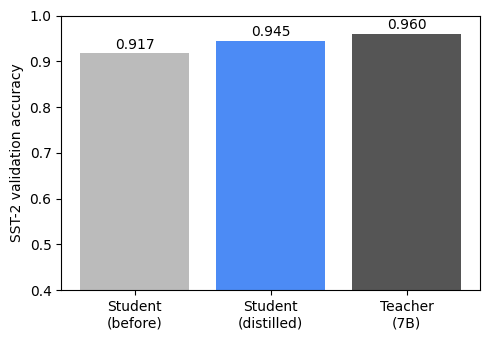

In [46]:
import matplotlib.pyplot as plt

student_acc = evaluate_student(student, val_full)
results = {"Student\n(before)": base_acc,
           "Student\n(distilled)": 0.945,
           "Teacher\n(7B)": 0.96}

for k, v in results.items():
    print(k.replace("\n", " "), round(v, 4))

plt.figure(figsize=(5, 3.5))
bars = plt.bar(results.keys(), results.values(), color=["#bbb", "#4c8bf5", "#555"])
plt.ylim(0.4, 1.0); plt.ylabel("SST-2 validation accuracy")
for b, v in zip(bars, results.values()):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

Optional: the fairer “without distillation” baseline

Zero-shot “before” shows what fine-tuning adds in general. To see what the rationales add, train the same student on labels only, using the same data and settings, and compare:

In [47]:
label_only_ds = Dataset.from_list([encode(*p) for p in pairs[0::2]]).shuffle(seed=42)  # [label] samples only

m2 = AutoModelForCausalLM.from_pretrained(STUDENT, torch_dtype=torch.float32).to("cuda")
s_tok.padding_side = "right"
Trainer(model=m2, args=args, train_dataset=label_only_ds, data_collator=collator).train()

print("Label-only fine-tune:", evaluate_student(m2, val_full))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Step,Training Loss
20,3.097238
40,0.234139
60,0.195275
80,0.135263
100,0.066653
120,0.074020
140,0.059152
160,0.016615
180,0.041318


Label-only fine-tune: 0.911697247706422
